In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
import seaborn as sns

In [34]:
df = pd.read_csv('data/boston.csv')

Làm sạch dữ liệu

In [35]:
# 1. Kiểm tra dữ liệu thiếu
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

print("Số lượng missing values:")
print(missing)

print("\nTỷ lệ missing (%):")
print(missing_percent)


Số lượng missing values:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

Tỷ lệ missing (%):
CRIM       0.0
ZN         0.0
INDUS      0.0
CHAS       0.0
NOX        0.0
RM         0.0
AGE        0.0
DIS        0.0
RAD        0.0
TAX        0.0
PTRATIO    0.0
B          0.0
LSTAT      0.0
MEDV       0.0
dtype: float64


In [36]:
# 2. Kiểm tra giá trị trùng lặp 
duplicates = df.duplicated().sum()
print("Số dòng trùng lặp:", duplicates)

# Xóa nếu cần
df_clean = df.drop_duplicates()

Số dòng trùng lặp: 0


In [37]:
# 3. Kiểm tra kiểu dữ liệu
print(df.dtypes)

CRIM       float64
ZN         float64
INDUS      float64
CHAS         int64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD          int64
TAX        float64
PTRATIO    float64
B          float64
LSTAT      float64
MEDV       float64
dtype: object


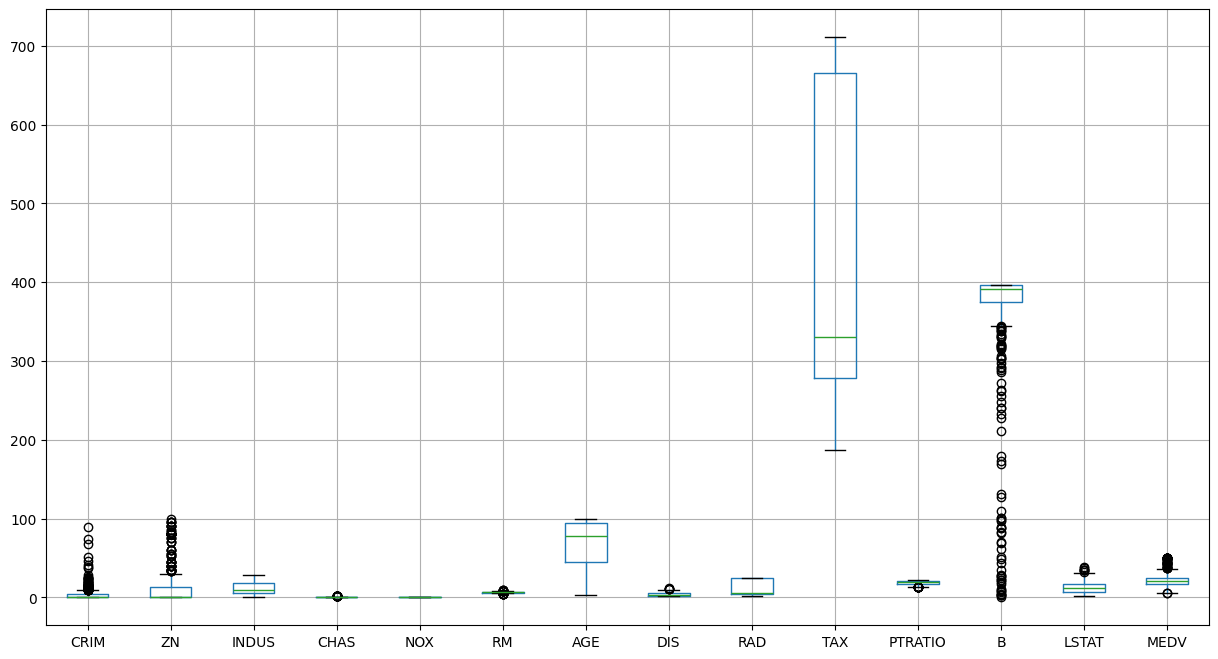

Số lượng outlier mỗi cột:
CRIM       66
ZN         68
INDUS       0
CHAS       35
NOX         0
RM         30
AGE         0
DIS         5
RAD         0
TAX         0
PTRATIO    15
B          77
LSTAT       7
MEDV       40
dtype: int64


In [38]:
#4. Kiểm tra giá trị ngoại lai
df.boxplot(figsize=(15,8))
plt.show()
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

outliers = ((df < (Q1 - 1.5*IQR)) | (df > (Q3 + 1.5*IQR)))
outlier_count = outliers.sum()

print("Số lượng outlier mỗi cột:")
print(outlier_count)

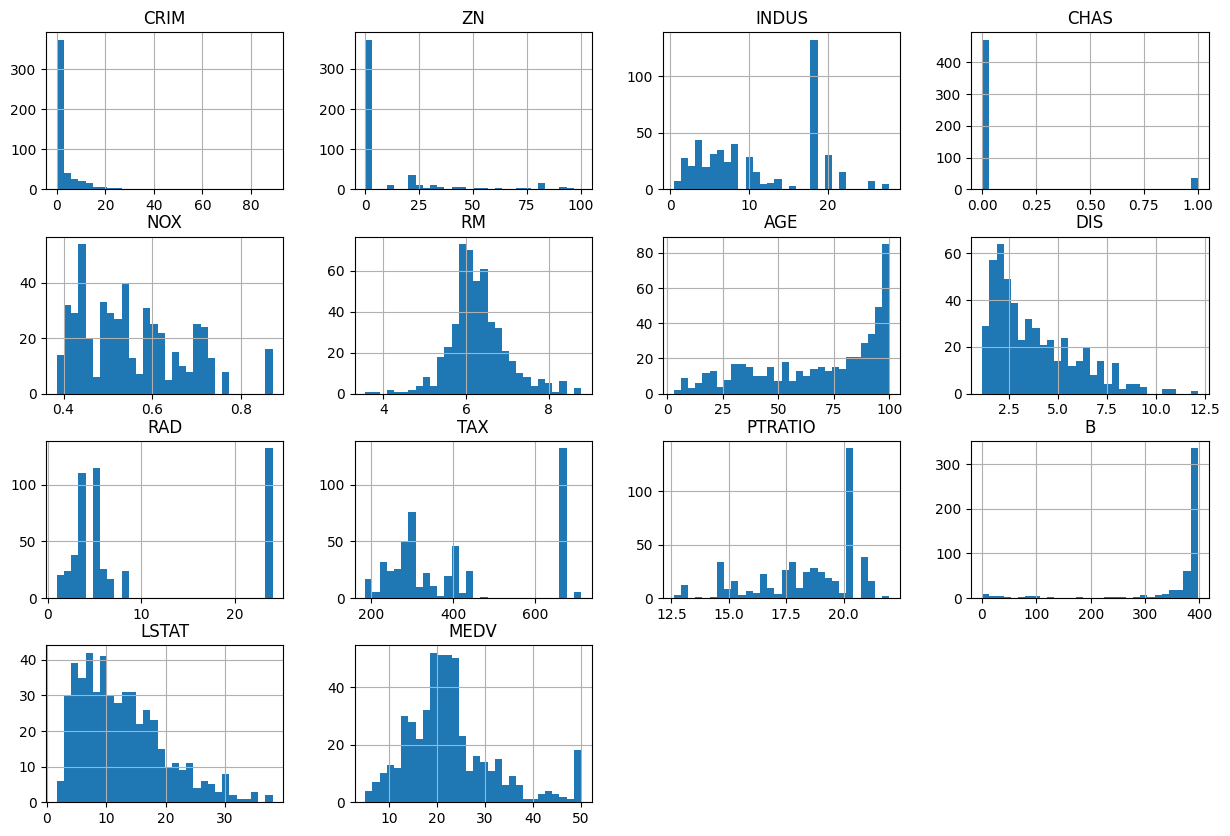

In [39]:
#5. Kiểm tra phân phối
df.hist(figsize=(15,10), bins=30)
plt.show()

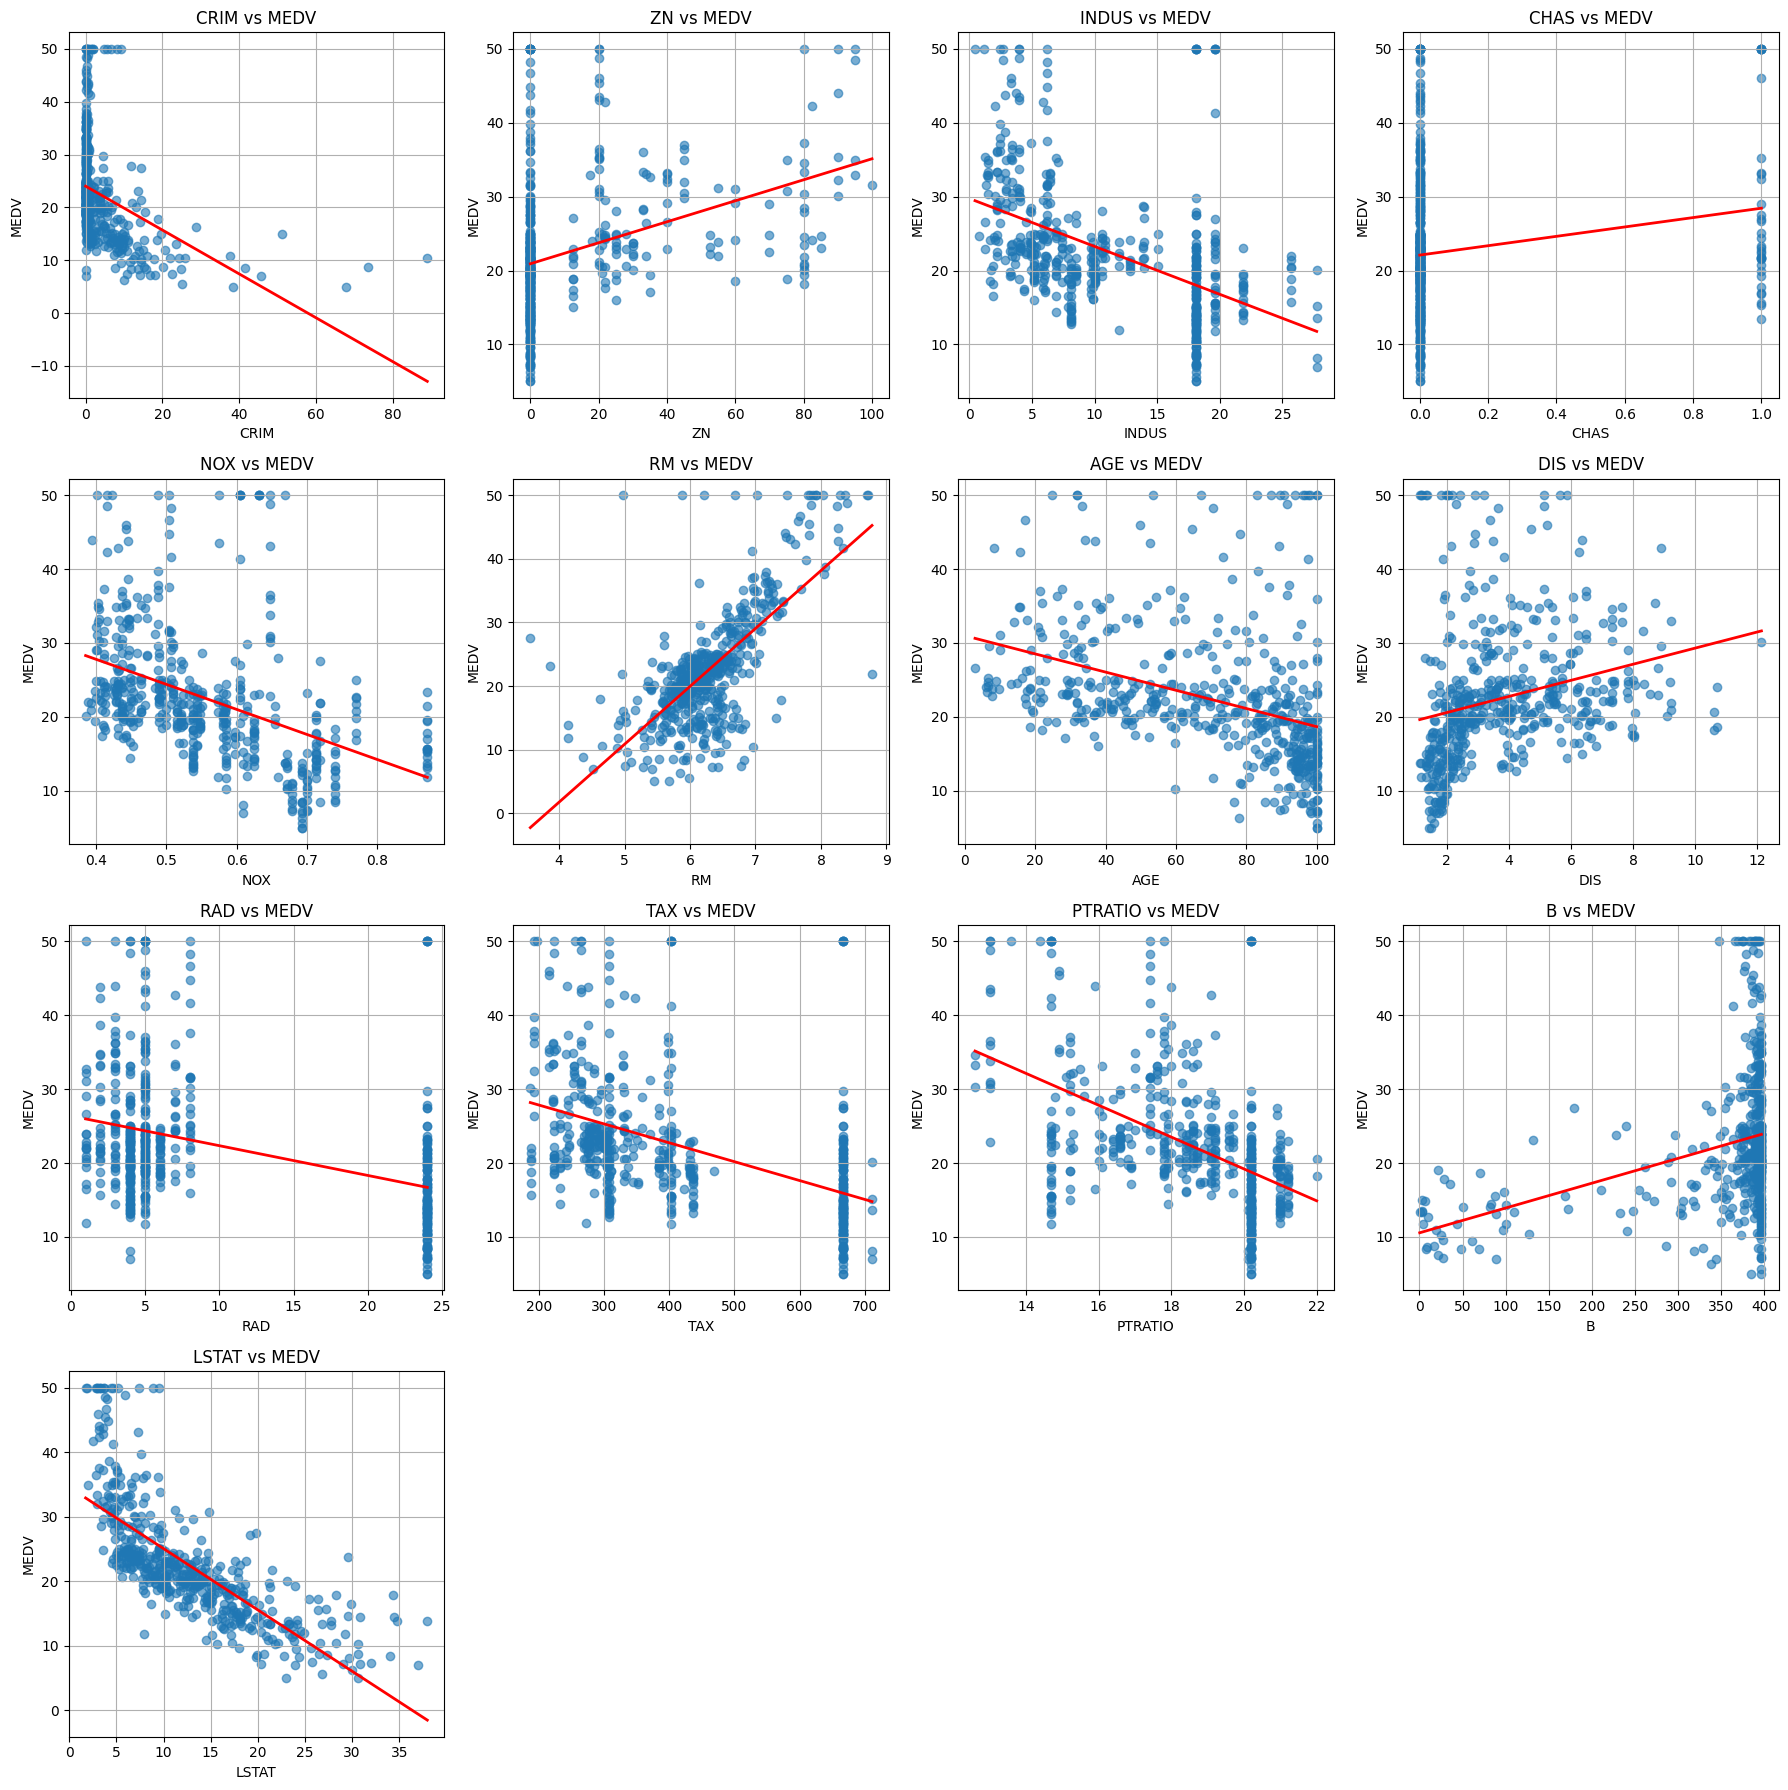

In [40]:
target_col = 'MEDV'

feature_cols = [col for col in df.columns if col != target_col]

rows, cols = 4, 4
plt.figure(figsize=(18, 18))

for i, col in enumerate(feature_cols):
    X = df[[col]].values
    Y = df[target_col].values

    model = LinearRegression()
    model.fit(X, Y)

    X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    Y_pred = model.predict(X_range)

    ax = plt.subplot(rows, cols, i + 1)

    ax.scatter(X, Y, alpha=0.6, label="Data")
    ax.plot(X_range, Y_pred, color='red', linewidth=2, label="Linear Fit")

    ax.set_title(f'{col} vs MEDV')
    ax.set_xlabel(col)
    ax.set_ylabel('MEDV')
    ax.grid(True)

total = rows * cols
if len(feature_cols) < total:
    for j in range(len(feature_cols) + 1, total + 1):
        ax = plt.subplot(rows, cols, j)
        ax.axis("off")

plt.tight_layout()
plt.show()

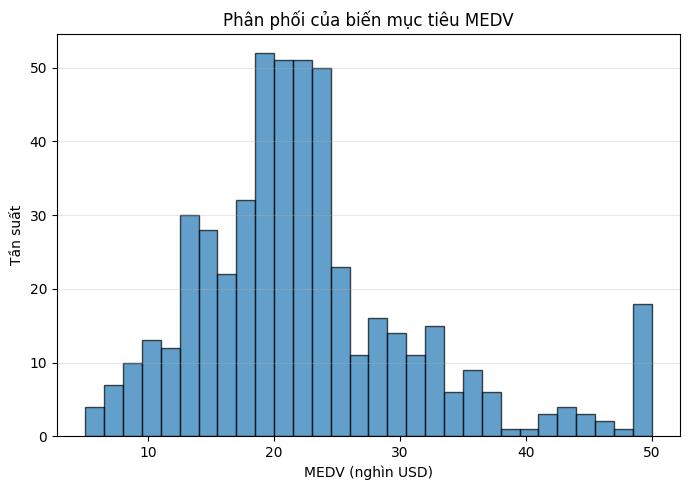

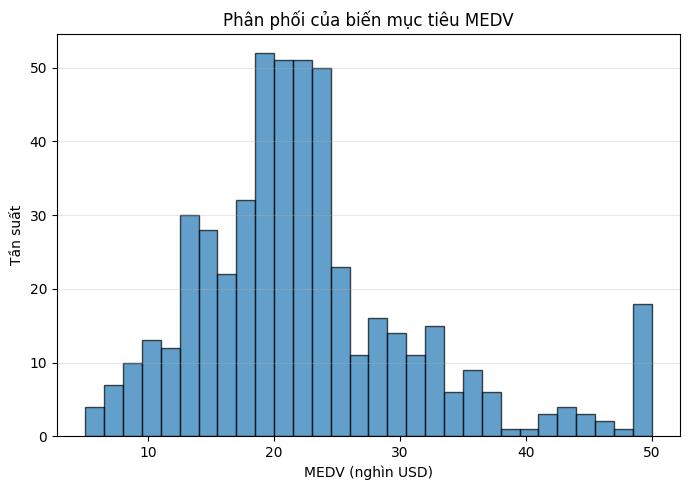

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.hist(df['MEDV'], bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('MEDV (nghìn USD)')
plt.ylabel('Tần suất')
plt.title('Phân phối của biến mục tiêu MEDV')
plt.grid(axis='y', alpha=0.3)

# Lưu hình để chèn vào LaTeX
plt.tight_layout()
plt.show()


Không bỏ đi các giá trị ngoại lai do dùng chung cho cả 2 mô hình 

In [43]:
df['CRIM'] = np.log1p(df['CRIM'])
df['ZN'] = np.log1p(df['ZN'])
df['B'] = np.log1p(df['B'])
df['LSTAT'] = np.log1p(df['LSTAT'])
df['B'] = np.sqrt(df['B'])

In [44]:
# Chuẩn hóa dữ liệu
from sklearn.preprocessing import StandardScaler
# Dùng cho hồi quy tuyến tính
scaler = StandardScaler()
X_linear = scaler.fit_transform(df.drop('MEDV', axis=1))
y = df['MEDV']
# Dùng cho rừng hồi quy
X_tree = df.drop('MEDV', axis=1)
y = df['MEDV']


In [45]:
# RM
q1, q99 = df['RM'].quantile([0.05, 0.95])
df['RM'] = df['RM'].clip(q1, q99)


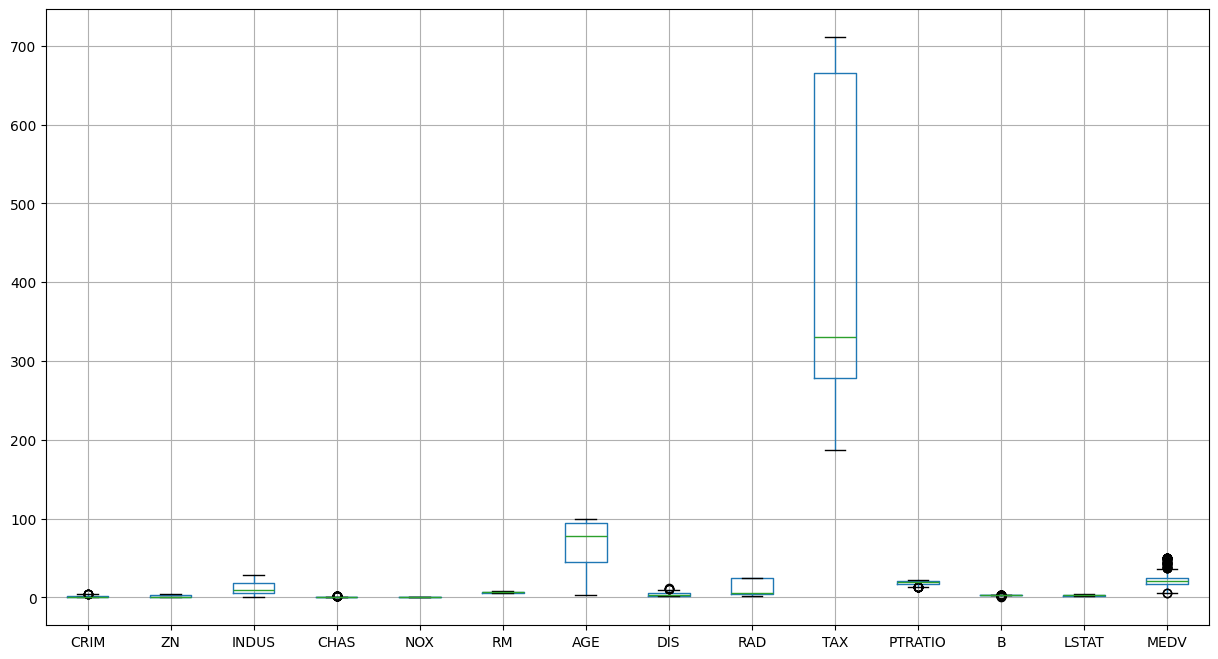

Số lượng outlier mỗi cột:
CRIM        6
ZN          0
INDUS       0
CHAS       35
NOX         0
RM          0
AGE         0
DIS         5
RAD         0
TAX         0
PTRATIO    15
B          78
LSTAT       0
MEDV       40
dtype: int64


In [46]:
#4. Kiểm tra giá trị ngoại lai
df.boxplot(figsize=(15,8))
plt.show()
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1

outliers = ((df < (Q1 - 1.5*IQR)) | (df > (Q3 + 1.5*IQR)))
outlier_count = outliers.sum()

print("Số lượng outlier mỗi cột:")
print(outlier_count)

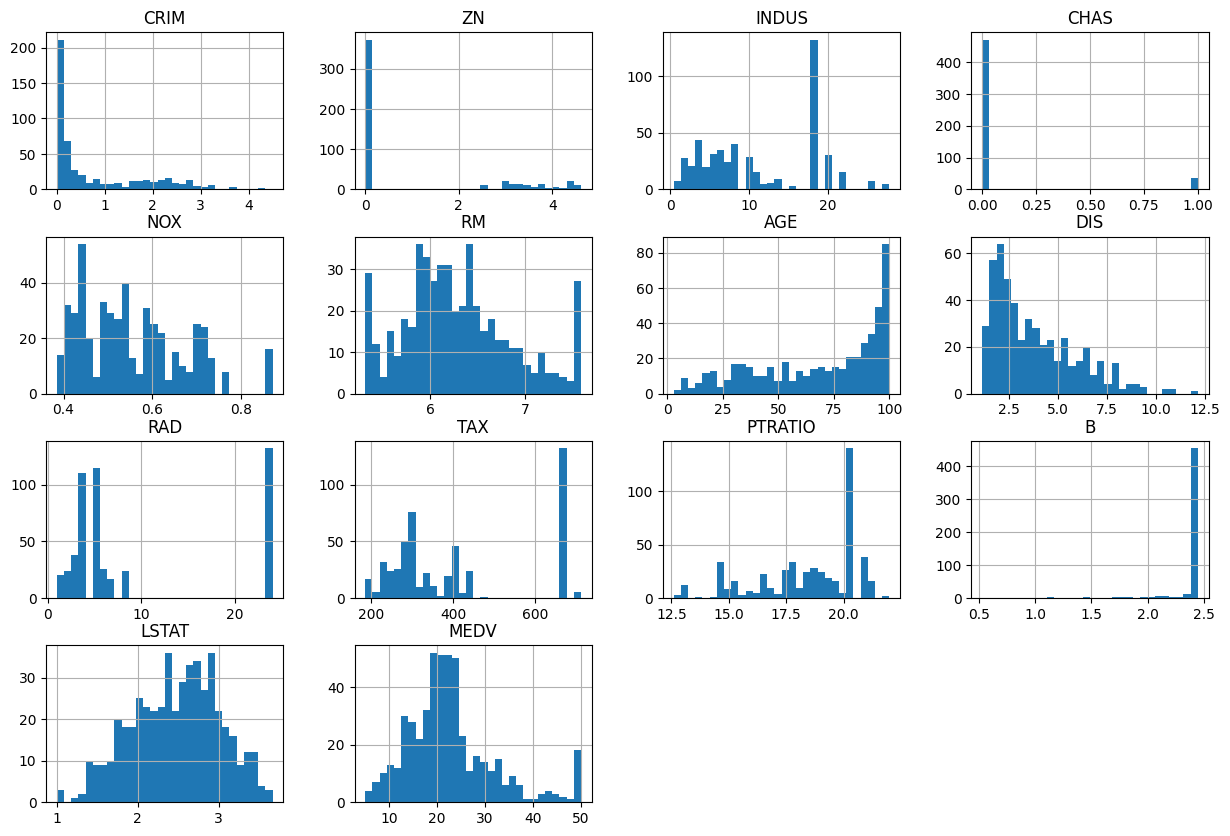

In [47]:
#5. Kiểm tra phân phối
df.hist(figsize=(15,10), bins=30)
plt.show()

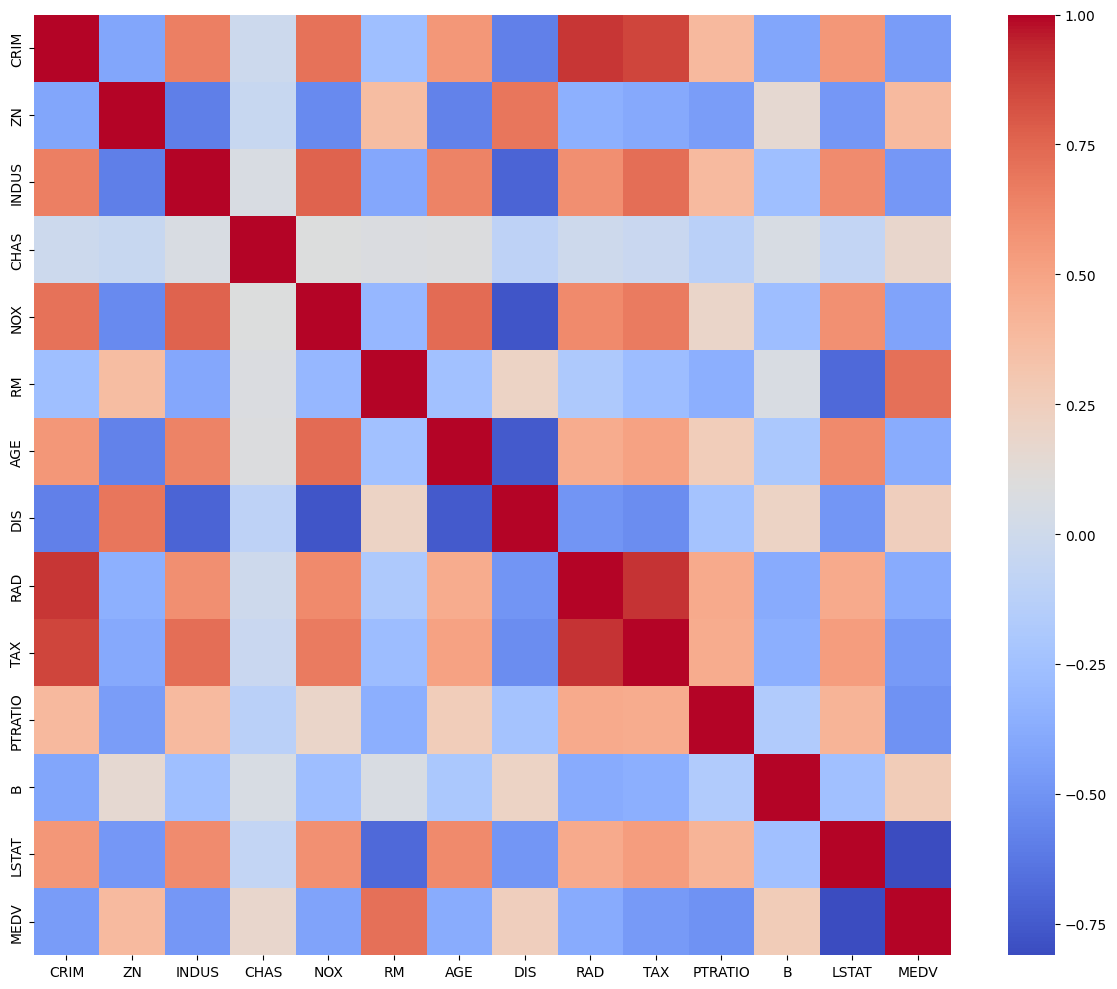

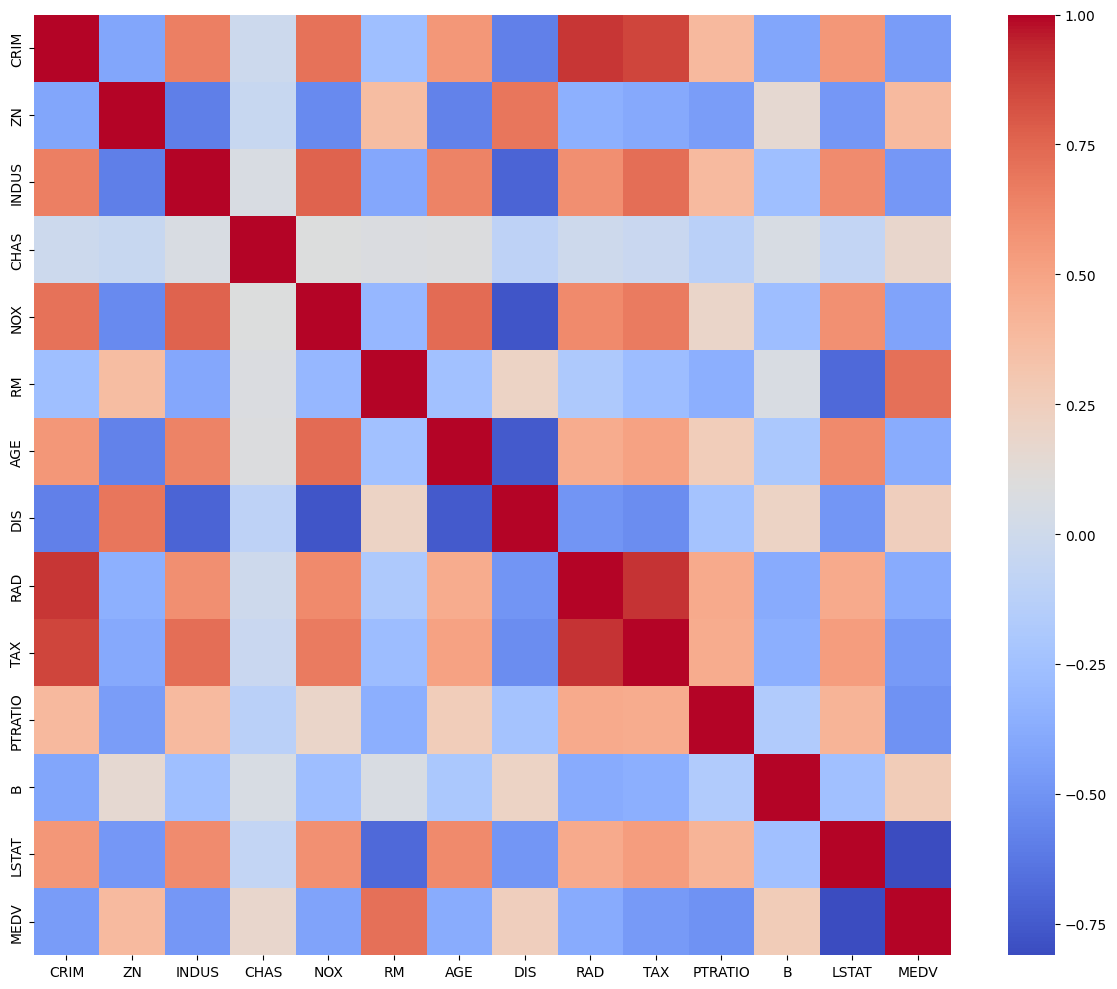

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=False, cmap="coolwarm")
plt.tight_layout()
plt.show()

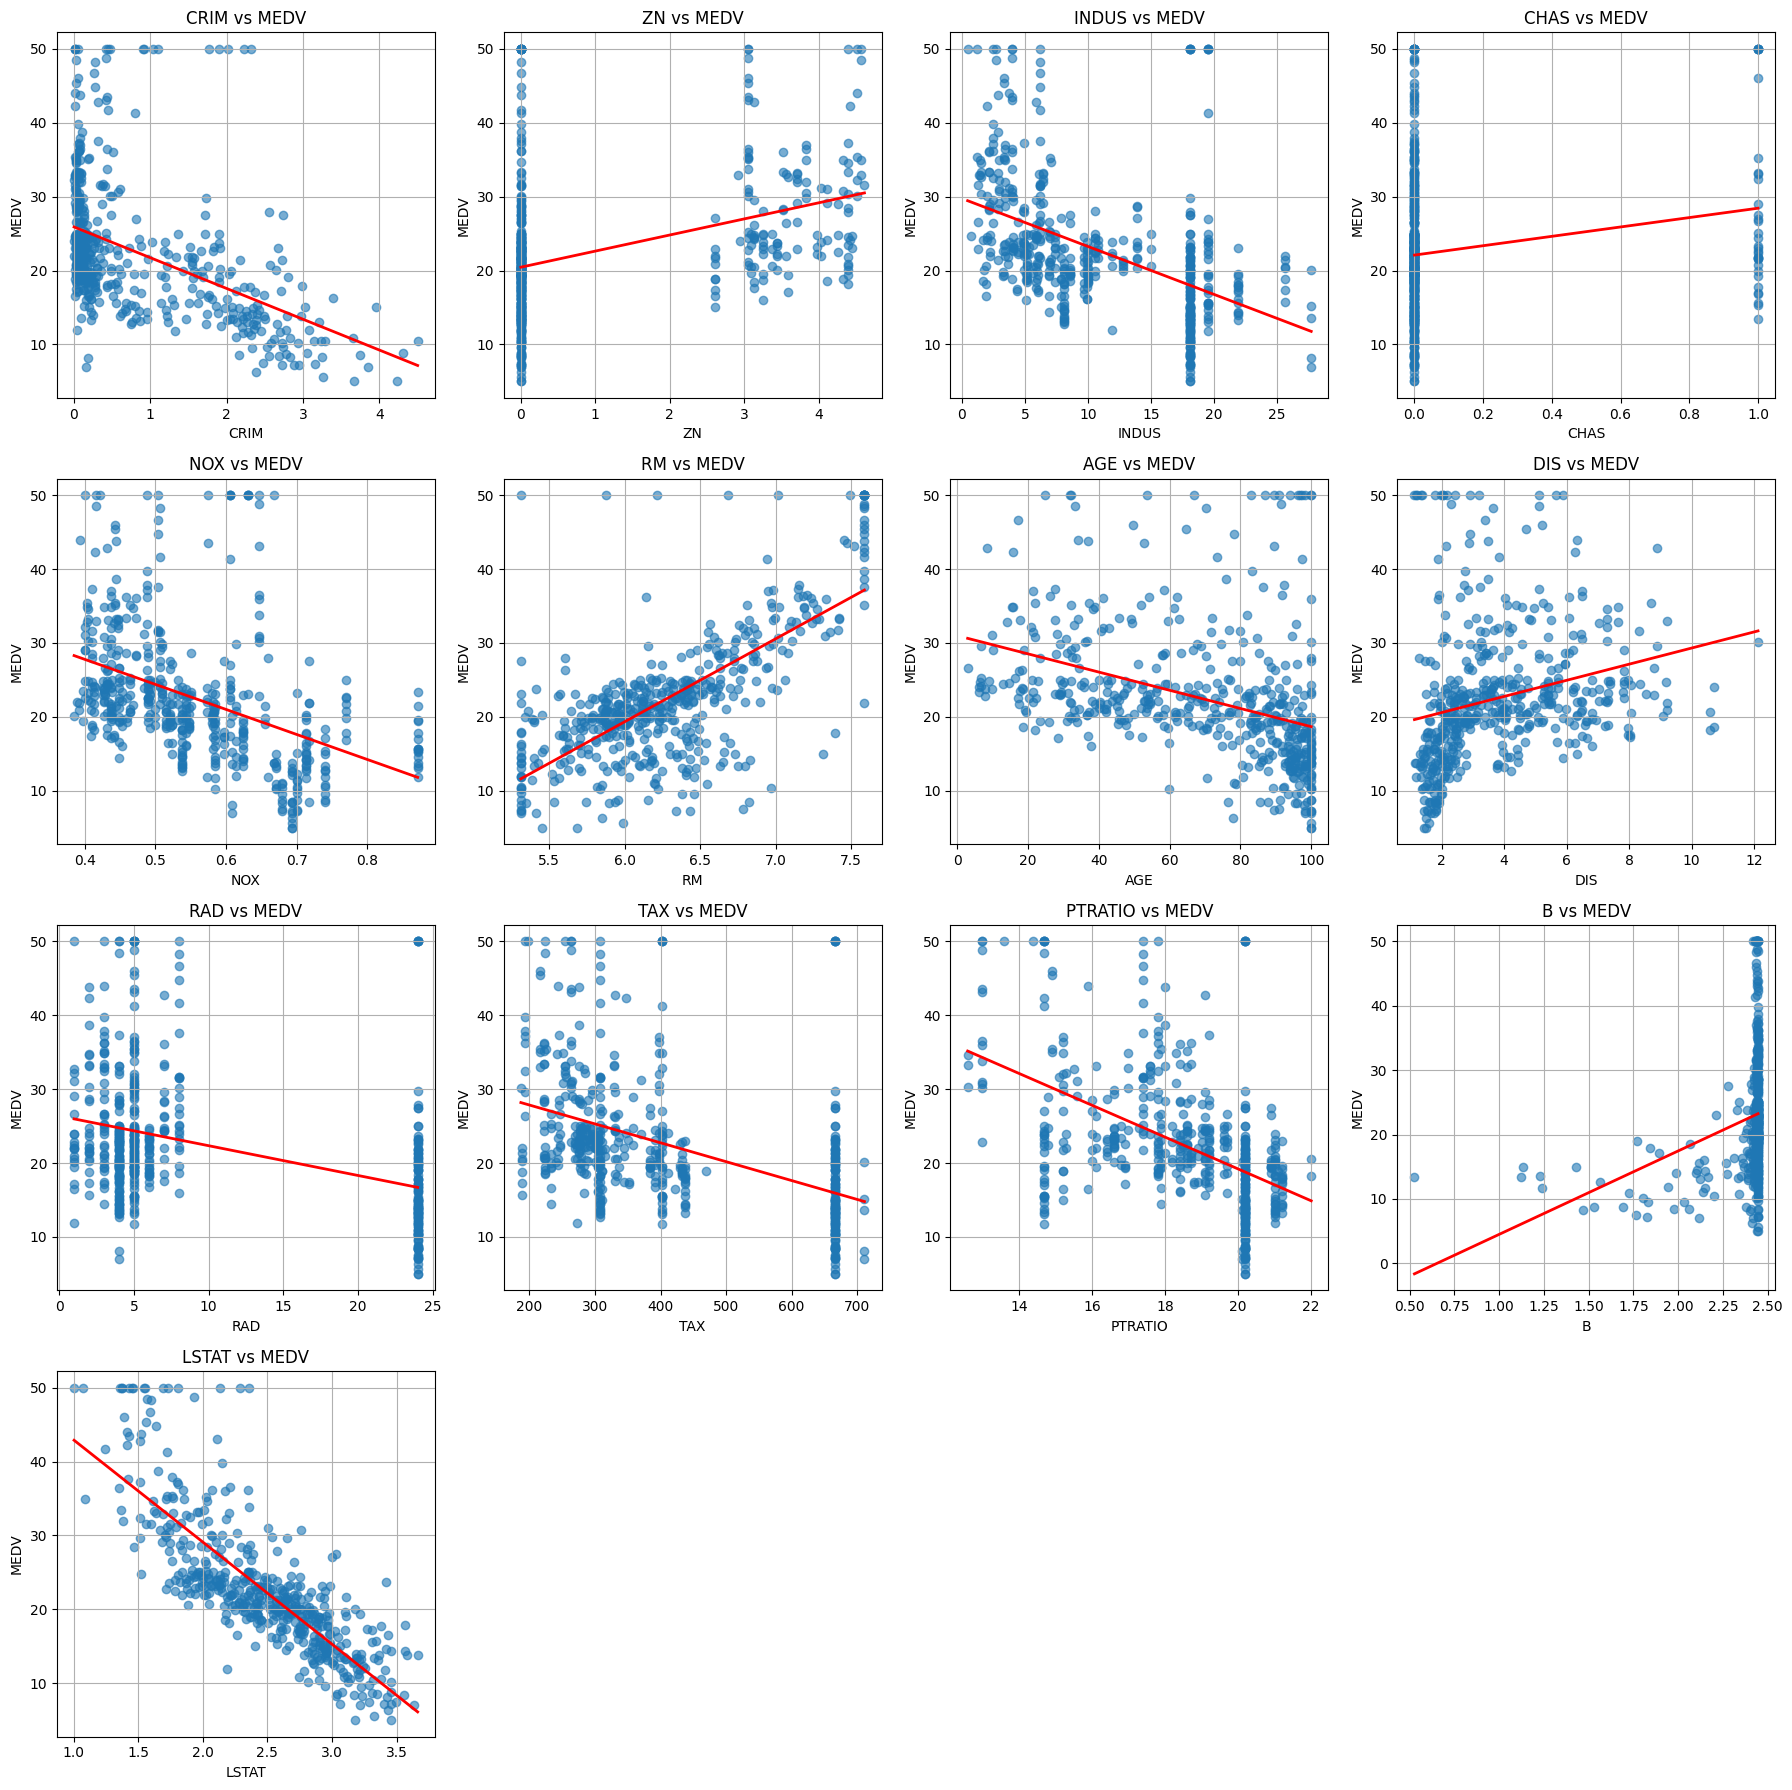

In [50]:
target_col = 'MEDV'

feature_cols = [col for col in df.columns if col != target_col]

rows, cols = 4, 4
plt.figure(figsize=(18, 18))

for i, col in enumerate(feature_cols):
    X = df[[col]].values
    Y = df[target_col].values

    model = LinearRegression()
    model.fit(X, Y)

    X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    Y_pred = model.predict(X_range)

    ax = plt.subplot(rows, cols, i + 1)

    ax.scatter(X, Y, alpha=0.6, label="Data")
    ax.plot(X_range, Y_pred, color='red', linewidth=2, label="Linear Fit")

    ax.set_title(f'{col} vs MEDV')
    ax.set_xlabel(col)
    ax.set_ylabel('MEDV')
    ax.grid(True)

total = rows * cols
if len(feature_cols) < total:
    for j in range(len(feature_cols) + 1, total + 1):
        ax = plt.subplot(rows, cols, j)
        ax.axis("off")

plt.tight_layout()
plt.show()

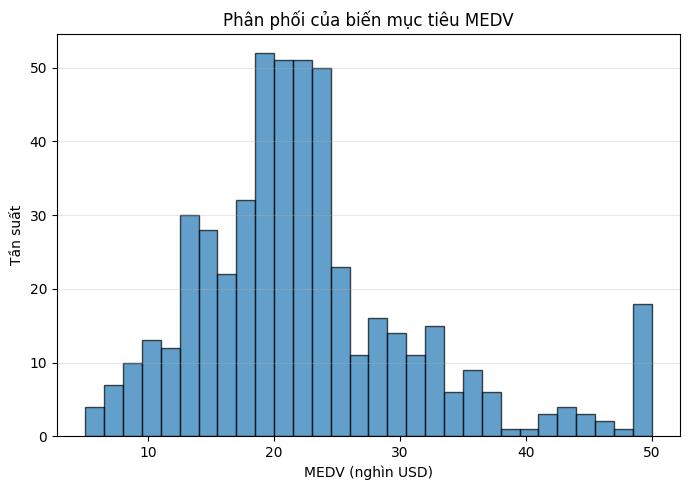

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.hist(df['MEDV'], bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('MEDV (nghìn USD)')
plt.ylabel('Tần suất')
plt.title('Phân phối của biến mục tiêu MEDV')
plt.grid(axis='y', alpha=0.3)

# Lưu hình để chèn vào LaTeX
plt.tight_layout()
plt.show()

In [52]:
from sklearn.model_selection import train_test_split

X = df.drop('MEDV', axis=1)
y = df['MEDV']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [53]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=5, random_state=42)

# 5-fold Cross Validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    dt, 
    X_train, 
    y_train, 
    scoring="neg_root_mean_squared_error",
    cv=cv
)

print(f"Cross-Validation RMSE: {-scores.mean():.2f}")


Cross-Validation RMSE: 5.27


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import randint

param_dist_rf = {
    'n_estimators': randint(100, 500),
    'max_depth': randint(3, 20),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 20),
    'max_features': ['auto', 'sqrt', 'log2']
}

rf = RandomForestRegressor(random_state=42)

random_search_rf = RandomizedSearchCV(
    rf,
    param_distributions=param_dist_rf,
    n_iter=50,
    cv=5,
    random_state=42,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

random_search_rf.fit(X_train, y_train)

print("Best params RF:", random_search_rf.best_params_)

best_params_rf = random_search_rf.best_params_
best_score_rf = random_search_rf.best_score_

print(f"Best Parameters (Random Search RF): {best_params_rf}")
print(f"Best CV Score (Random Search RF): {best_score_rf:.2f}")


c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
80 fits failed out of a total of 250.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
48 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1356, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "c:\U

Best params RF: {'max_depth': 19, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 6, 'n_estimators': 323}
Best Parameters (Random Search RF): {'max_depth': 19, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 6, 'n_estimators': 323}
Best CV Score (Random Search RF): -3.81


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    max_depth        = best_params_rf['max_depth'],
    min_samples_split= best_params_rf['min_samples_split'],
    min_samples_leaf = best_params_rf['min_samples_leaf'],
    n_estimators     = best_params_rf['n_estimators'],
    max_features     = best_params_rf['max_features'],
    random_state=42
)

rf_model.fit(X_train, y_train)


,n_estimators,323
,criterion,'squared_error'
,max_depth,19
,min_samples_split,6
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor

param_dist_dt = {
    'max_depth': randint(1, 100),
    'min_samples_split': randint(2, 100),
    'min_samples_leaf': randint(1, 100),
}

dtree_reg = DecisionTreeRegressor(random_state=42)

random_search_dt = RandomizedSearchCV(
    dtree_reg, 
    param_distributions=param_dist_dt, 
    n_iter=100, 
    cv=5, 
    random_state=42,
    scoring='neg_root_mean_squared_error'
)

random_search_dt.fit(X_train, y_train)

best_params_dt = random_search_dt.best_params_
best_score_dt = random_search_dt.best_score_

print(f"Best Parameters (Random Search DT): {best_params_dt}")
print(f"Best Score (Random Search DT): {best_score_dt:.2f}")


Best Parameters (Random Search DT): {'max_depth': 67, 'min_samples_leaf': 19, 'min_samples_split': 21}
Best Score (Random Search DT): -4.57


In [ ]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth        = best_params_dt['max_depth'],
    min_samples_split= best_params_dt['min_samples_split'],
    min_samples_leaf = best_params_dt['min_samples_leaf'],
)

dt_model.fit(X_train, y_train)


,criterion,'squared_error'
,splitter,'best'
,max_depth,67
,min_samples_split,21
,min_samples_leaf,19
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [54]:
# Linear
lr_train_pred = lr_model.predict(X_train)
lr_test_pred  = lr_model.predict(X_test)

# Random Forest
rf_train_pred = rf_model.predict(X_train)
rf_test_pred  = rf_model.predict(X_test)

# Decision Tree
dt_train_pred = dt_model.predict(X_train)
dt_test_pred  = dt_model.predict(X_test)

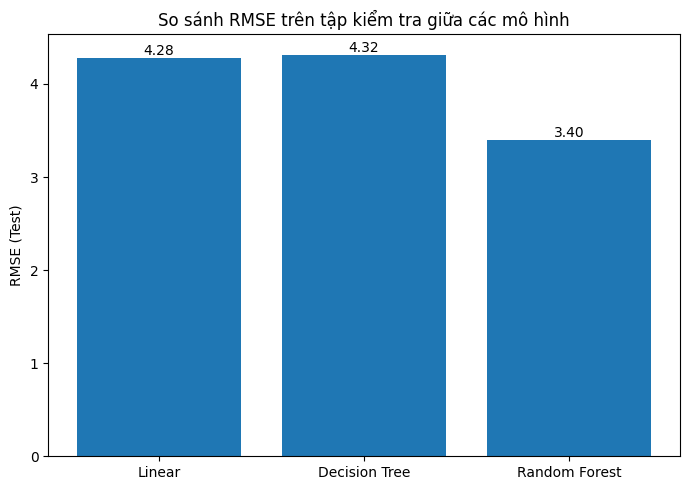

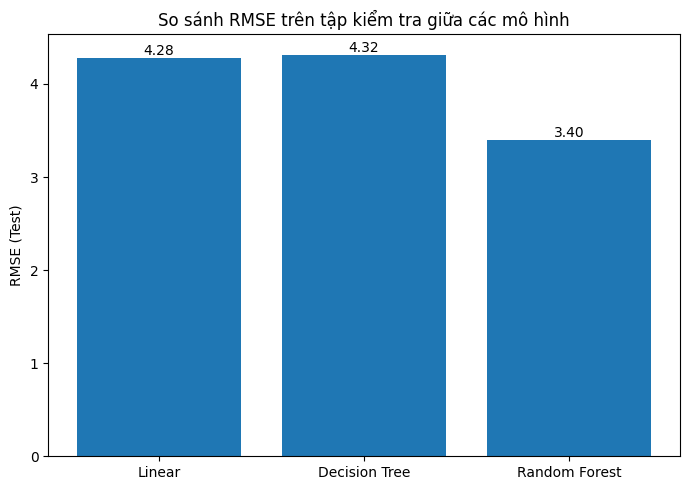

RMSE (Test):
  Linear Regression   : 4.2807
  Decision Tree       : 4.3161
  Random Forest       : 3.4014

R2 (Test):
  Linear Regression   : 0.7501
  Decision Tree       : 0.7460
  Random Forest       : 0.8422


In [56]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

def get_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    return rmse, r2

# Tính chỉ số trên tập Test
lr_rmse_test, lr_r2_test = get_metrics(y_test, lr_test_pred)
dt_rmse_test, dt_r2_test = get_metrics(y_test, dt_test_pred)
rf_rmse_test, rf_r2_test = get_metrics(y_test, rf_test_pred)

models = ['Linear', 'Decision Tree', 'Random Forest']
rmse_values = [lr_rmse_test, dt_rmse_test, rf_rmse_test]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, rmse_values)
plt.ylabel('RMSE (Test)')
plt.title('So sánh RMSE trên tập kiểm tra giữa các mô hình')

# Ghi giá trị lên đầu cột
for bar, val in zip(bars, rmse_values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{val:.2f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print("RMSE (Test):")
print(f"  Linear Regression   : {lr_rmse_test:.4f}")
print(f"  Decision Tree       : {dt_rmse_test:.4f}")
print(f"  Random Forest       : {rf_rmse_test:.4f}")

print("\nR2 (Test):")
print(f"  Linear Regression   : {lr_r2_test:.4f}")
print(f"  Decision Tree       : {dt_r2_test:.4f}")
print(f"  Random Forest       : {rf_r2_test:.4f}")


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

def eval_model(y_true, y_pred, name=""):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"===> {name}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2  : {r2:.2f}")
    print("-" * 30)
    return rmse


In [ ]:
#Hồi quy tuyến tính
eval_model(y_train, lr_train_pred, "Linear - Train")
eval_model(y_test,  lr_test_pred,  "Linear - Test")

===> Linear - Train
RMSE: 4.27
R2  : 0.79
------------------------------
===> Linear - Test
RMSE: 4.28
R2  : 0.75
------------------------------


np.float64(4.28072978376725)

In [ ]:
#Rừng cây hồi quy
eval_model(y_train, rf_train_pred, "Random Forest - Train")
eval_model(y_test,  rf_test_pred,  "Random Forest - Test")

===> Random Forest - Train
RMSE: 2.13
R2  : 0.95
------------------------------
===> Random Forest - Test
RMSE: 3.40
R2  : 0.84
------------------------------


np.float64(3.401377194612552)

In [ ]:
#Cây hồi quy
eval_model(y_train, dt_train_pred, "Decision Tree - Train")
eval_model(y_test,  dt_test_pred,  "Decision Tree - Test")

===> Decision Tree - Train
RMSE: 4.01
R2  : 0.81
------------------------------
===> Decision Tree - Test
RMSE: 4.32
R2  : 0.75
------------------------------


np.float64(4.316138032187579)

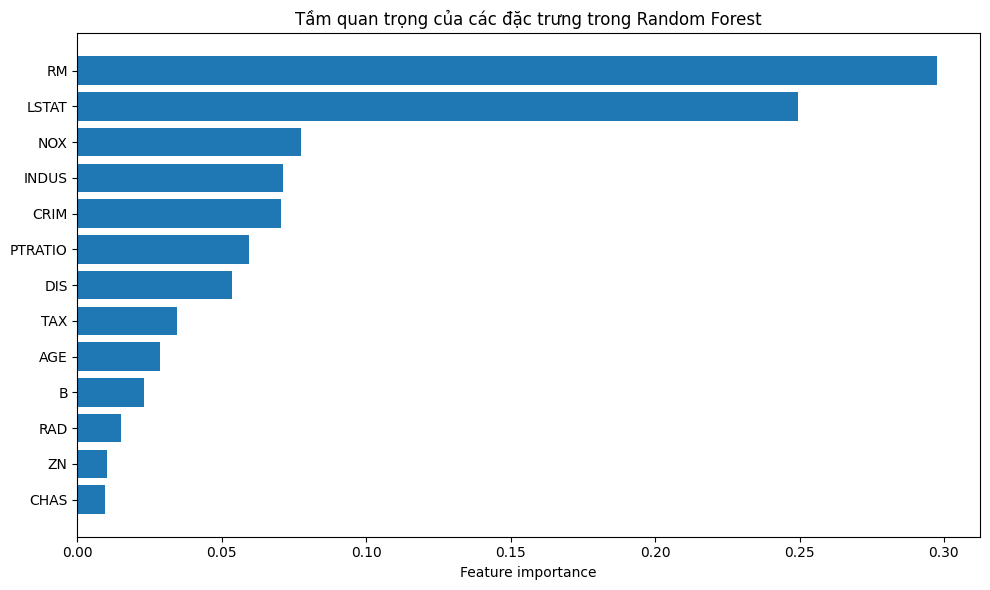

In [57]:
import numpy as np
import matplotlib.pyplot as plt

# Lấy importance và sắp xếp giảm dần
importances = rf_model.feature_importances_
feature_names = X_train.columns

indices = np.argsort(importances)[::-1]  # chỉ số sắp xếp giảm dần

plt.figure(figsize=(10, 6))
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), feature_names[indices])
plt.gca().invert_yaxis()  # Đặc trưng quan trọng nhất nằm trên cùng
plt.xlabel('Feature importance')
plt.title('Tầm quan trọng của các đặc trưng trong Random Forest')

plt.tight_layout()
plt.show()
